In [1]:
from pathlib import Path
import csv

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import find_peaks
from statsmodels.graphics.tsaplots import plot_acf

In [2]:
log_path = Path("../../data/loghub/HDFS_v1/HDFS.log")
if not log_path.exists():
    log_path = Path("data/loghub/HDFS_v1/HDFS.log")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (14, 4),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "grid.alpha": 0.3,
    "legend.frameon": False,
})

In [3]:
chunks = pd.read_csv(
    log_path,
    sep=r"\s+",
    header=None,
    usecols=[0, 1],
    dtype=str,
    quoting=csv.QUOTE_NONE,
    chunksize=250_000,
)

parts = []
starts = []
ends = []
processed_count = 0

In [4]:
for chunk in chunks:
    chunk.columns = ["date", "time"]
    timestamps = pd.to_datetime(
        chunk["date"] + chunk["time"],
        format="%y%m%d%H%M%S",
    )
    parts.append(timestamps.dt.floor("min").value_counts())
    starts.append(timestamps.min())
    ends.append(timestamps.max())
    processed_count += len(chunk)

first_time = min(starts)
last_time = max(ends)
time_index = pd.date_range(first_time.floor("min"), last_time.floor("min"), freq="min")

activity = pd.concat(parts).groupby(level=0).sum()
activity = activity.reindex(time_index, fill_value=0).rename("log_records")
assert activity.sum() == processed_count

print("Записей лога:", processed_count)
print("Начало:", first_time)
print("Конец:", last_time)

Записей лога: 11175629
Начало: 2008-11-09 20:35:18
Конец: 2008-11-11 11:16:28


## 1. Динамика

Посмотрим, как число записей лога менялось со временем.

Период наблюдений составляет **38,7 часа**.

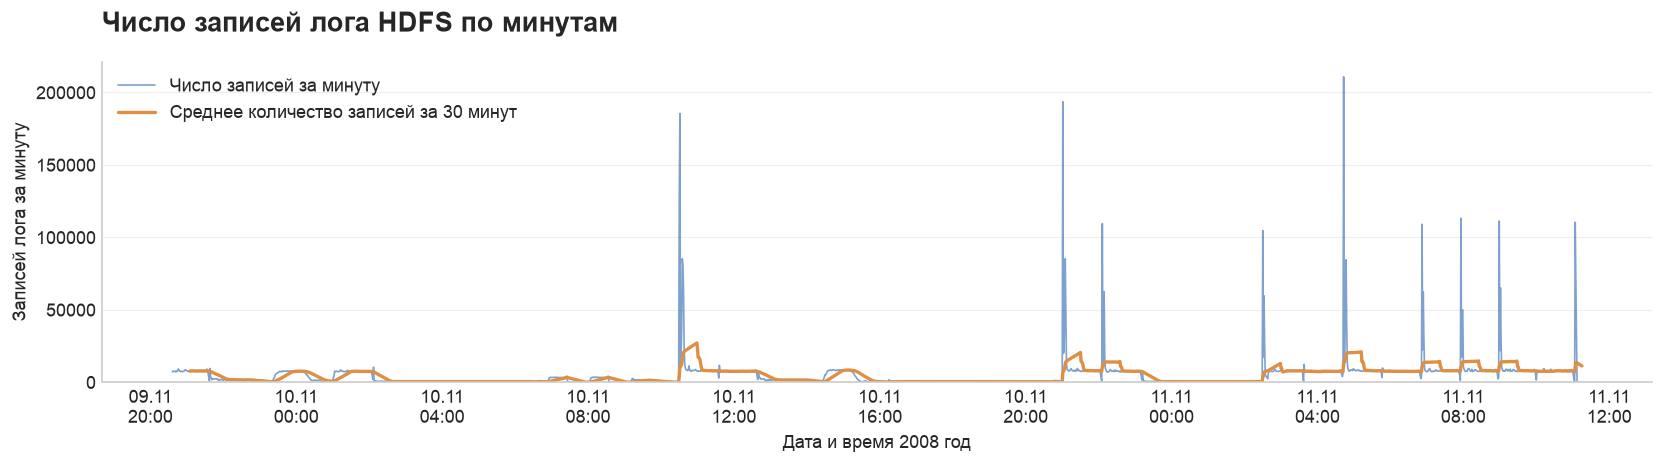

In [37]:
fig, ax = plt.subplots()
ax.plot(activity.index, activity, color="#3B6FB6", alpha=0.65, linewidth=1, label="Число записей за минуту")
ax.plot(activity.index, activity.rolling(30).mean(), color="#DE8F44", linewidth=2, label="Среднее количество записей за 30 минут")
ax.set_title("Число записей лога HDFS по минутам")
ax.set_xlabel("Дата и время 2008 год")
ax.set_ylabel("Записей лога за минуту")
ax.set_ylim(bottom=0)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m\n%H:%M"))
ax.legend()
plt.tight_layout()
plt.show()

**Вывод:** На графике чередуются периоды с небольшим числом записей и резкие пики; их причина пока не установлена.

In [34]:
summary = pd.Series({
    "Минимум": activity.min(),
    "Медиана": activity.median(),
    "Среднее": activity.mean(),
    "Максимум": activity.max(),
})
display(summary.round(1).to_frame("Записей логов за минуту"))
print("Время максимума:", activity.idxmax())

,Записей логов за минуту
Минимум,7.0
Медиана,1641.5
Среднее,4816.1
Максимум,210778.0


Время максимума: 2008-11-11 04:43:00


**Вывод:** Максимум 210 778 записей в минуту (11.11.2008, 04:43) более чем в 40 раз выше среднего (4 816). Причину такого пика предстоит выяснить.

## 2. Сезонность

Проверим, есть ли сезонность.

In [7]:
peak_positions, _ = find_peaks(activity, height=activity.quantile(0.99), distance=10)
peaks = activity.iloc[peak_positions]

peak_intervals = peaks.to_frame("Записей лога за минуту")
peak_intervals["Интервал после предыдущего максимума, мин"] = peaks.index.to_series().diff().dt.total_seconds() / 60
display(peak_intervals)

,Записей лога за минуту,"Интервал после предыдущего максимума, мин"
2008-11-10 10:31:00,185420,NaN
2008-11-10 21:01:00,193604,630.0
2008-11-10 22:06:00,109471,65.0
2008-11-11 02:30:00,104684,264.0
2008-11-11 04:43:00,210778,133.0
2008-11-11 06:52:00,109028,129.0
2008-11-11 07:56:00,113175,64.0
2008-11-11 08:59:00,111285,63.0
2008-11-11 11:04:00,110351,125.0


**Вывод:** Наблюдение длится всего 38,7 часа, этого мало для оценки суточной сезонности. Постоянного периода повторения не видно; сезонность по этой таблице не подтверждена.

## 3. Автокорреляция

Положительная корреляция означает, что большему числу записей в одну минуту чаще соответствует большее число записей в другую. Значение около нуля означает слабую линейную связь.

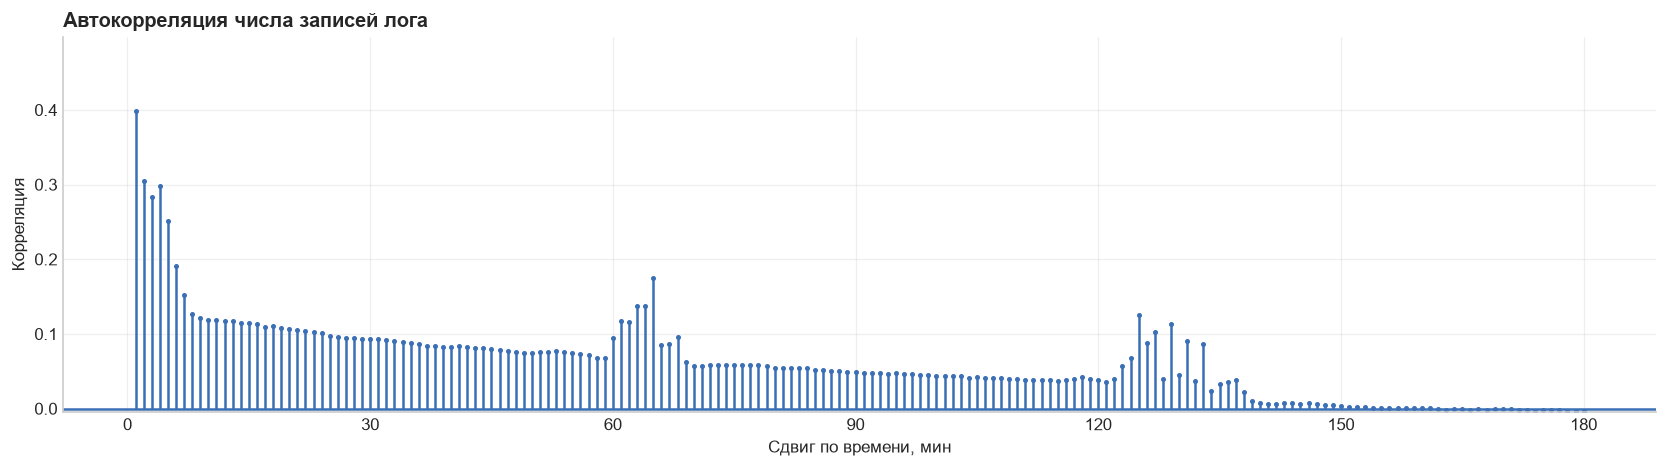

In [8]:
fig, ax = plt.subplots()
plot_acf(activity, alpha=None, lags=180, zero=False, fft=True, ax=ax, auto_ylims=True,
         color="#3B6FB6", markersize=2, vlines_kwargs={"colors": "#3B6FB6"})
ax.set_title("Автокорреляция числа записей лога")
ax.set_xlabel("Сдвиг по времени, мин")
ax.set_ylabel("Корреляция")
ax.set_xticks(range(0, 181, 30))
plt.tight_layout()
plt.show()

**Вывод:** При увеличении сдвига корреляция в целом снижается, хотя есть подъемы около 60-65 и 120-140, но они не доказывают сезонность.

In [9]:
lags = [1, 5, 15, 30, 60, 65, 120, 125, 180]
correlations = pd.DataFrame({
    "Сдвиг по времени, мин": lags,
    "Автокорреляция": [activity.autocorr(lag) for lag in lags],
})
display(correlations.round(3))

,"Сдвиг по времени, мин",Автокорреляция
0,1,0.398
1,5,0.252
2,15,0.118
3,30,0.096
4,60,0.097
5,65,0.181
6,120,0.039
7,125,0.129
8,180,-0.003


**Вывод:** Корреляция соседей за минуту равна 0,398, а при сдвиге она падает. Близкие по времени значения связаны сильнее, чем значения с более сильной разницей.

## 4. Стационарность

Для стационарного ряда средний уровень и разброс не должны меняться со временем. 

In [10]:
periods = []
for number in range(4):
    start = number * len(activity) // 4
    end = (number + 1) * len(activity) // 4
    part = activity.iloc[start:end]
    periods.append({
        "Часть": number + 1,
        "Начало": part.index.min(),
        "Конец": part.index.max(),
        "Среднее": part.mean(),
        "Медиана": part.median(),
        "Разброс": part.std(),
    })

period_summary = pd.DataFrame(periods).set_index("Часть")
display(period_summary.round(1))

<ipython-input-1-e57b0445295d>:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(period_summary.round(1))


,Начало,Конец,Среднее,Медиана,Разброс
Часть,,,,,
1,2008-11-09 20:35:00,2008-11-10 06:14:00,2860.4,854.0,3190.6
2,2008-11-10 06:15:00,2008-11-10 15:55:00,4168.9,1628.0,11182.2
3,2008-11-10 15:56:00,2008-11-11 01:35:00,3054.9,458.0,10960.1
4,2008-11-11 01:36:00,2008-11-11 11:16:00,9161.1,7639.0,14674.7


**Вывод:** В последней части среднее число записей примерно в 3,2 раза выше, чем в первой: с 2 860 до 9 161. Разброс тоже больше: с 3 191 до 14 675. Части записи заметно различаются по этим двум показателям, поэтому ряд нестационарный.

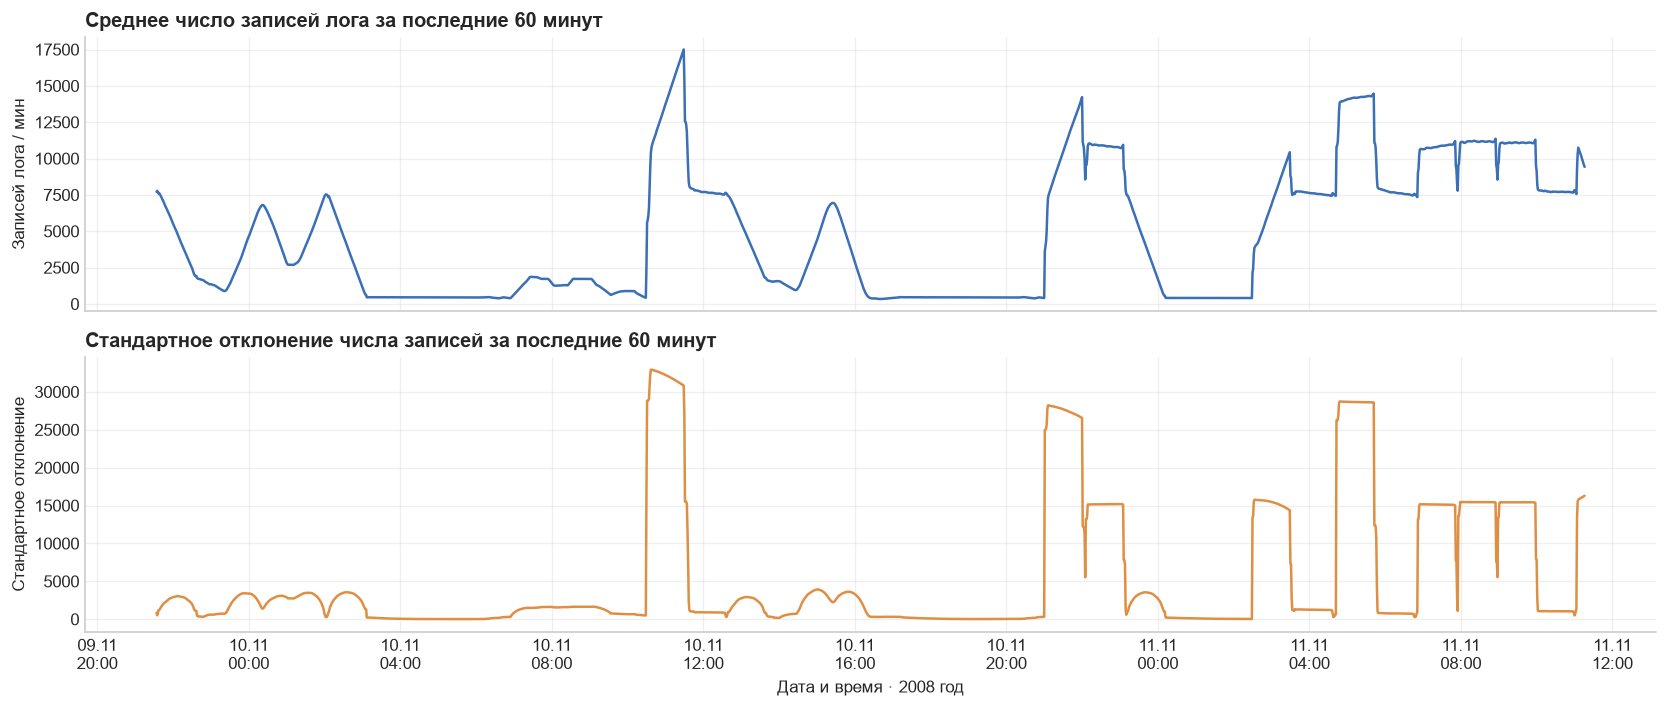

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(activity.index, activity.rolling(60).mean(), color="#3B6FB6")
axes[0].set_title("Среднее число записей лога за последние 60 минут")
axes[0].set_ylabel("Записей лога / мин")

axes[1].plot(activity.index, activity.rolling(60).std(), color="#DE8F44")
axes[1].set_title("Стандартное отклонение числа записей за последние 60 минут")
axes[1].set_ylabel("Стандартное отклонение")
axes[1].set_xlabel("Дата и время · 2008 год")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m\n%H:%M"))
plt.tight_layout()
plt.show()

**Вывод:** Верхний график показывает изменения среднего числа записей, нижний - изменения разброса. Обе линии меняются со временем, поэтому постоянство среднего и разброса для всего ряда не подтверждено.

## 5. Выводы

**Динамика**

На графике чередуются периоды с небольшим числом записей и резкие пики; их причина пока не установлена. Максимум 210 778 записей в минуту (11.11.2008, 04:43) более чем в 40 раз выше среднего (4 816).

**Сезонность**

Наблюдение длится всего 38,7 часа, этого мало для оценки суточной сезонности. Постоянного периода повторения не видно; сезонность по этой таблице не подтверждена.

**Автокорреляция**

При увеличении сдвига корреляция в целом снижается, хотя есть подъемы около 60-65 и 120-140 минут, но они не доказывают сезонность.

Корреляция соседних минут равна 0,398, а при сдвиге она падает. Близкие по времени значения связаны сильнее, чем удаленные.

**Стационарность**

В последней части среднее число записей примерно в 3,2 раза выше, чем в первой: с 2 860 до 9 161. Разброс тоже больше: с 3 191 до 14 675. Части записи заметно различаются по этим двум показателям, поэтому ряд нестационарный.

Скользящие среднее и стандартное отклонение за 60 минут тоже меняются со временем, поэтому постоянство среднего и разброса для всего ряда не подтверждено.

**Гипотеза о пиках.** Данных пока мало, чтобы объяснить пики. Рабочая гипотеза: часть ресурсоемких задач запускают по расписанию утром и вечером, когда пользовательская активность ниже, чтобы уменьшить нагрузку на кластер днем. Такие задачи могут создавать большое количество записей лога и объяснять наблюдаемые пики.